In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Load the dataset
df = pd.read_csv("sales_data.csv")

# Display the first five rows
display(df.head())

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales
0,2024-01-01,Phone,7,37300,CUST001,East,261100
1,2024-01-02,Headphones,4,15406,CUST002,North,61624
2,2024-01-03,Phone,2,21746,CUST003,West,43492
3,2024-01-04,Headphones,1,30895,CUST004,East,30895
4,2024-01-05,Laptop,8,39835,CUST005,North,318680


Dataset shape: (100, 7)
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Date         100 non-null    str  
 1   Product      100 non-null    str  
 2   Quantity     100 non-null    int64
 3   Price        100 non-null    int64
 4   Customer_ID  100 non-null    str  
 5   Region       100 non-null    str  
 6   Total_Sales  100 non-null    int64
dtypes: int64(3), str(4)
memory usage: 5.6 KB

Missing values:
Date           0
Product        0
Quantity       0
Price          0
Customer_ID    0
Region         0
Total_Sales    0
dtype: int64

Duplicate rows: 0


In [3]:
# Select numerical columns
numeric_cols = ["Quantity", "Price", "Total_Sales"]

# Summary statistics
print("DESCRIPTIVE STATISTICS")
display(df[numeric_cols].describe())

# Individual statistics
for col in numeric_cols:
    print(f"\n{col}")
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode().tolist())
    print("Standard deviation:", df[col].std())
    print("Variance:", df[col].var())

DESCRIPTIVE STATISTICS


,Quantity,Price,Total_Sales
count,100.000000,100.000000,100.000000
mean,4.780000,25808.510000,123650.480000
std,2.588163,13917.630242,100161.085275
min,1.000000,1308.000000,6540.000000
25%,2.750000,14965.250000,39517.500000
50%,5.000000,24192.000000,97955.500000
75%,7.000000,38682.250000,175792.500000
max,9.000000,49930.000000,373932.000000



Quantity
Mean: 4.78
Median: 5.0
Mode: [4]
Standard deviation: 2.5881626414477625
Variance: 6.69858585858586

Price
Mean: 25808.51
Median: 24192.0
Mode: [1308, 2603, 3839, 4195, 4339, 4341, 4578, 5272, 6160, 6713, 6720, 7148, 7262, 7455, 7647, 9191, 9483, 11032, 11494, 11591, 11902, 13233, 13488, 13624, 14381, 15160, 15406, 15475, 16596, 16667, 16997, 17512, 17838, 17924, 18616, 18964, 19256, 19322, 19425, 19507, 19661, 20083, 20655, 20696, 20770, 21746, 23229, 23376, 23381, 24160, 24224, 25948, 26110, 27196, 28098, 29275, 29499, 29840, 30531, 30717, 30895, 32297, 32524, 32791, 34303, 34447, 34843, 34900, 35418, 36518, 37055, 37135, 37300, 38037, 38298, 39835, 39924, 40177, 40244, 40420, 40430, 40518, 41548, 41749, 42813, 43350, 43428, 43495, 43848, 43861, 44045, 44487, 44652, 45023, 45467, 45515, 48602, 48769, 49101, 49930]
Standard deviation: 13917.630241724111
Variance: 193700431.54535356

Total_Sales
Mean: 123650.48
Median: 97955.5
Mode: [6540, 6720, 7148, 7647, 10544, 13426, 15356

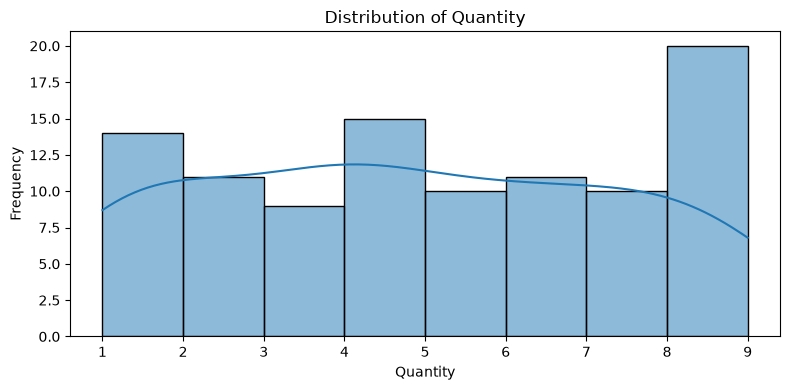

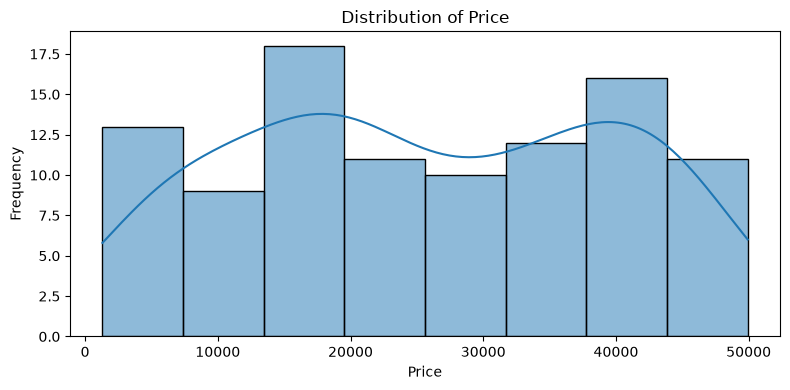

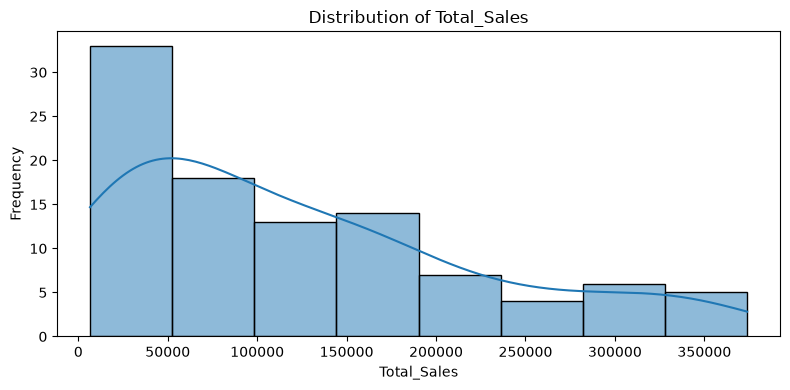

In [4]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

CORRELATION MATRIX


,Quantity,Price,Total_Sales
Quantity,1.000000,0.008014,0.688107
Price,0.008014,1.000000,0.646131
Total_Sales,0.688107,0.646131,1.000000


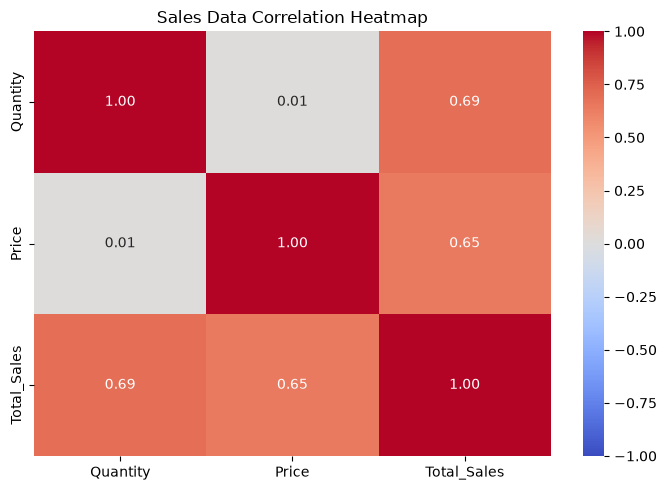

Quantity vs Total Sales
Pearson correlation: 0.6881
P-value: 0.0


In [5]:
# Pearson correlation matrix
corr = df[numeric_cols].corr()

print("CORRELATION MATRIX")
display(corr)

# Correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm",
            vmin=-1, vmax=1, fmt=".2f")
plt.title("Sales Data Correlation Heatmap")
plt.tight_layout()
plt.show()

# Individual Pearson correlation
r, p = stats.pearsonr(
    df["Quantity"], df["Total_Sales"]
)

print("Quantity vs Total Sales")
print("Pearson correlation:", round(r, 4))
print("P-value:", round(p, 4))

In [6]:
east = df.loc[
    df["Region"] == "East", "Total_Sales"
].dropna()

west = df.loc[
    df["Region"] == "West", "Total_Sales"
].dropna()

if len(east) >= 2 and len(west) >= 2:
    t_stat, p_value = stats.ttest_ind(
        east, west, equal_var=False
    )

    print("TEST 1: East vs West Sales")
    print("East average:", east.mean())
    print("West average:", west.mean())
    print("T-statistic:", t_stat)
    print("P-value:", p_value)
else:
    print("Not enough observations for the East-West t-test.")

TEST 1: East vs West Sales
East average: 132612.57894736843
West average: 81689.30769230769
T-statistic: 2.0623139687676573
P-value: 0.045478882283485886


In [7]:
region_groups = [
    group["Total_Sales"].dropna().to_numpy()
    for _, group in df.groupby("Region")
]

region_groups = [
    group for group in region_groups if len(group) >= 2
]

if len(region_groups) >= 2:
    f_stat, p_value = stats.f_oneway(*region_groups)

    print("TEST 2: Sales Across Regions (ANOVA)")
    print("F-statistic:", f_stat)
    print("P-value:", p_value)
else:
    print("Not enough region groups for ANOVA.")

TEST 2: Sales Across Regions (ANOVA)
F-statistic: 2.1643634298978425
P-value: 0.09723678084979993


In [8]:
product_groups = [
    group["Total_Sales"].dropna().to_numpy()
    for _, group in df.groupby("Product")
]

product_groups = [
    group for group in product_groups if len(group) >= 2
]

if len(product_groups) >= 2:
    f_stat, p_value = stats.f_oneway(*product_groups)

    print("TEST 3: Sales Across Products (ANOVA)")
    print("F-statistic:", f_stat)
    print("P-value:", p_value)
else:
    print("Not enough product groups for ANOVA.")

TEST 3: Sales Across Products (ANOVA)
F-statistic: 2.050791009479213
P-value: 0.09342819607538902


In [9]:
sales = df["Total_Sales"].dropna()

n = len(sales)
mean_sales = sales.mean()
std_sales = sales.std()

if n >= 2:
    standard_error = stats.sem(sales)

    lower, upper = stats.t.interval(
        confidence=0.95,
        df=n - 1,
        loc=mean_sales,
        scale=standard_error
    )

    print("Mean Sales:", round(mean_sales, 2))
    print("95% Confidence Interval:")
    print("Lower limit:", round(lower, 2))
    print("Upper limit:", round(upper, 2))
    print("Margin of error:", round(upper - mean_sales, 2))

Mean Sales: 123650.48
95% Confidence Interval:
Lower limit: 103776.35
Upper limit: 143524.61
Margin of error: 19874.13


In [10]:
# Prepare data for regression
regression_data = df[
    ["Total_Sales", "Quantity", "Price"]
].dropna()

# Build the linear regression model
model = smf.ols(
    "Total_Sales ~ Quantity + Price",
    data=regression_data
).fit()

# Display regression results
print(model.summary())

print("\nR-squared:", round(model.rsquared, 4))

                            OLS Regression Results                            
Dep. Variable:            Total_Sales   R-squared:                       0.884
Model:                            OLS   Adj. R-squared:                  0.882
Method:                 Least Squares   F-statistic:                     369.3
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           4.40e-46
Time:                        22:44:07   Log-Likelihood:                -1185.2
No. Observations:                 100   AIC:                             2376.
Df Residuals:                      97   BIC:                             2384.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1.217e+05   9668.294    -12.586      0.0

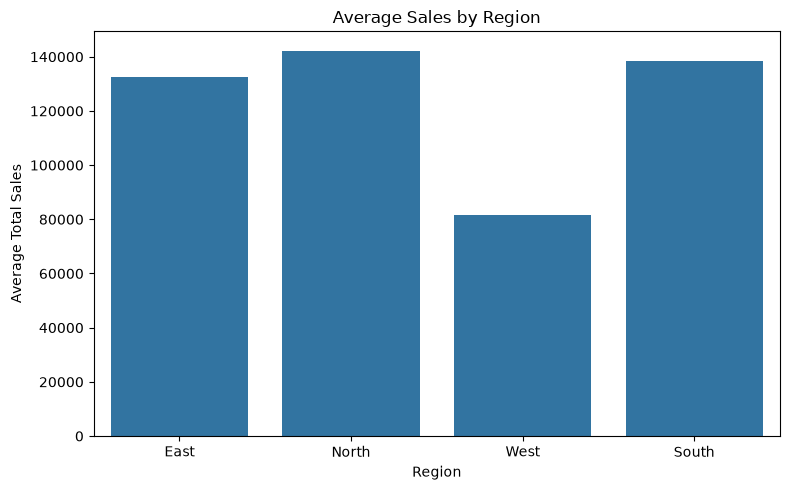

In [11]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Region",
    y="Total_Sales",
    errorbar=None
)

plt.title("Average Sales by Region")
plt.xlabel("Region")
plt.ylabel("Average Total Sales")
plt.tight_layout()
plt.savefig("sales_by_region.png", dpi=300)
plt.show()

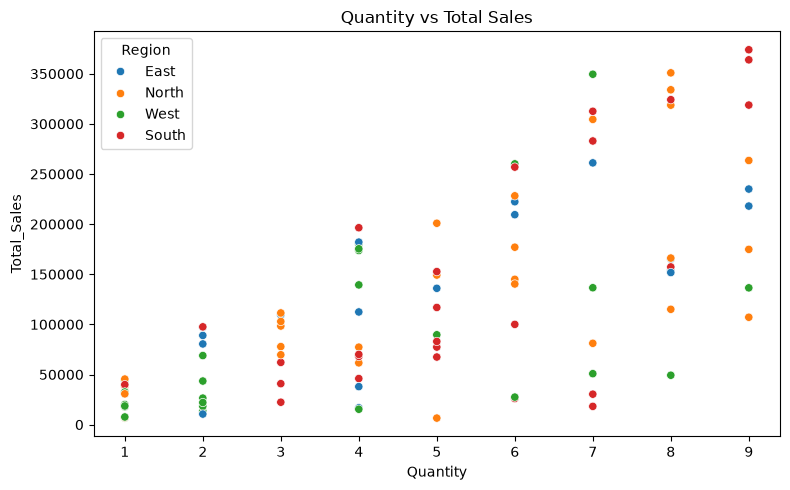

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Total_Sales",
    hue="Region"
)

plt.title("Quantity vs Total Sales")
plt.tight_layout()
plt.savefig("quantity_vs_sales.png", dpi=300)
plt.show()

In [13]:
results = []

# Test 1: East vs West
east = df.loc[df["Region"] == "East", "Total_Sales"].dropna()
west = df.loc[df["Region"] == "West", "Total_Sales"].dropna()

if len(east) >= 2 and len(west) >= 2:
    t, p = stats.ttest_ind(east, west, equal_var=False)
    results.append(
        f"Test 1 - East vs West sales\n"
        f"East mean: {east.mean():.2f}\n"
        f"West mean: {west.mean():.2f}\n"
        f"Statistic: {t:.4f}\nP-value: {p:.6f}\n"
        f"Conclusion: {'Significant difference' if p < 0.05 else 'No statistically significant difference'}\n"
    )

# Test 2: Sales by region
groups = [
    g["Total_Sales"].dropna().to_numpy()
    for _, g in df.groupby("Region")
]
groups = [g for g in groups if len(g) >= 2]

if len(groups) >= 2:
    f, p = stats.f_oneway(*groups)
    results.append(
        f"Test 2 - ANOVA by region\n"
        f"F-statistic: {f:.4f}\nP-value: {p:.6f}\n"
        f"Conclusion: {'Significant difference among regions' if p < 0.05 else 'No statistically significant difference detected'}\n"
    )

# Test 3: Sales by product
groups = [
    g["Total_Sales"].dropna().to_numpy()
    for _, g in df.groupby("Product")
]
groups = [g for g in groups if len(g) >= 2]

if len(groups) >= 2:
    f, p = stats.f_oneway(*groups)
    results.append(
        f"Test 3 - ANOVA by product\n"
        f"F-statistic: {f:.4f}\nP-value: {p:.6f}\n"
        f"Conclusion: {'Significant difference among products' if p < 0.05 else 'No statistically significant difference detected'}\n"
    )

with open("hypothesis_tests_results.txt", "w", encoding="utf-8") as file:
    file.write("HYPOTHESIS TEST RESULTS\n")
    file.write("=======================\n\n")
    file.write("\n".join(results))

print("Saved hypothesis_tests_results.txt")

Saved hypothesis_tests_results.txt


In [14]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Table, TableStyle, Image, PageBreak
)
from reportlab.lib.units import inch

# Calculate report metrics
sales = df["Total_Sales"].dropna()
corr = df[["Quantity", "Price", "Total_Sales"]].corr()

n = len(sales)
mean_sales = sales.mean()

if n >= 2:
    ci = stats.t.interval(
        0.95, df=n - 1,
        loc=mean_sales, scale=stats.sem(sales)
    )
else:
    ci = (float("nan"), float("nan"))

styles = getSampleStyleSheet()
doc = SimpleDocTemplate(
    "statistical_report.pdf",
    pagesize=A4
)

story = []

story.append(Paragraph(
    "Statistical Business Analysis Report", styles["Title"]
))
story.append(Spacer(1, 12))

story.append(Paragraph(
    "Objective: Analyze business sales data using "
    "descriptive statistics, hypothesis testing, "
    "correlation, confidence intervals and regression.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

story.append(Paragraph(
    "1. Dataset Overview", styles["Heading2"]
))
overview = [
    ["Metric", "Value"],
    ["Number of records", str(len(df))],
    ["Number of columns", str(len(df.columns))],
    ["Average sales", f"{mean_sales:,.2f}"],
    ["Median sales", f"{sales.median():,.2f}"],
    ["Sales standard deviation", f"{sales.std():,.2f}"],
    ["Minimum sales", f"{sales.min():,.2f}"],
    ["Maximum sales", f"{sales.max():,.2f}"],
]
table = Table(overview, colWidths=[220, 180])
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 7),
]))
story.append(table)
story.append(Spacer(1, 15))

story.append(Paragraph(
    "2. Confidence Interval", styles["Heading2"]
))
story.append(Paragraph(
    f"95% confidence interval for mean sales: "
    f"{ci[0]:,.2f} to {ci[1]:,.2f}.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

story.append(Paragraph(
    "3. Correlation Analysis", styles["Heading2"]
))
story.append(Paragraph(
    f"Correlation between quantity and total sales: "
    f"{corr.loc['Quantity', 'Total_Sales']:.4f}.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

story.append(Paragraph(
    "4. Regression Analysis", styles["Heading2"]
))
story.append(Paragraph(
    f"R-squared: {model.rsquared:.4f}. "
    "The model estimates the association of quantity and "
    "price with total sales. Interpret results in light "
    "of the dataset's sales calculation.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

story.append(Paragraph(
    "5. Sales Visualizations", styles["Heading2"]
))

for chart_file in [
    "sales_by_region.png",
    "quantity_vs_sales.png"
]:
    try:
        story.append(Image(
            chart_file, width=6*inch, height=3.5*inch
        ))
        story.append(Spacer(1, 10))
    except Exception as e:
        print("Could not add chart:", chart_file, e)

story.append(Paragraph(
    "6. Business Recommendations", styles["Heading2"]
))
story.append(Paragraph(
    "Compare average sales across regions and product "
    "categories. Use the hypothesis-test results to "
    "identify statistically supported differences. "
    "Investigate high-performing products and regions "
    "before making inventory or marketing decisions. "
    "Statistical association alone does not prove causation.",
    styles["BodyText"]
))

doc.build(story)

print("PDF created: statistical_report.pdf")

PDF created: statistical_report.pdf
